# Golden sample: cuts on the in\_ztf catalog

Two cuts, applied in order to the 14,898 in\_ztf candidates:

1. **dec < 75°** — PS1 imaging is unusable near the pole, so a ZTF-only detection there says nothing.
2. **Point-source test** — in every detected band, the brightest pixel must carry the fraction of the total flux that a star would carry at that signal-to-noise. A source more than 4σ below the stellar locus in any band is resolved and dropped.

Calibrated on the website labels (trash vs. Interesting?/Follow-up/Known/TNS), cut 2 removes **59% of trash and 5% of good**, and 18% of the unlabelled catalog. Everything below shows where those numbers come from.

In [17]:
import sys, sqlite3
sys.path.append('/Users/adamboesky/Research/long_transients')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.stats import mannwhitneyu

plt.rc('text', usetex=True)
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = 'cmr10'
mpl.rcParams['font.size'] = 12
mpl.rcParams['axes.formatter.use_mathtext'] = True
pd.set_option('display.width', 200)

DB = '/Users/adamboesky/Research/long_transients/Data/db'
# Live labels are on the host; this is the latest host -> laptop backup. Data/db/annotations.sqlite is stale.
ANNOTATIONS = '/Users/adamboesky/Research/long_transients/Data/backups/host_2026-10-26/annotations.sqlite'
BANDS = 'gri'

## Data: catalog rows and labels

In [18]:
src = pd.read_parquet(f'{DB}/sources.parquet')
src['catalog'] = src['catalog_tier'].map({'0': 'in_both', '1': 'in_ztf'})

ann = pd.read_sql('SELECT source_uuid, label, status FROM annotations', sqlite3.connect(ANNOTATIONS))
labels = ann.groupby('source_uuid')['label'].agg(lambda s: set(s.dropna()))
src['labels'] = src['source_uuid'].map(labels).apply(lambda v: v if isinstance(v, set) else set())
src['queued'] = src['source_uuid'].isin(ann.dropna(subset=['status']).source_uuid)

has = lambda name: src['labels'].apply(lambda L: name in L)
good = has('Interesting?') | has('Follow-up') | has('Known Transient') | src['queued'] | src['tns_matched'].fillna(False).astype(bool)
trash = has('Trash')
src['grp'] = np.select([trash & ~good, good & ~trash, src['labels'].apply(len) > 0], ['trash', 'good', 'other'], 'unlabelled')

ztf = src[src.catalog == 'in_ztf'].copy()
both = src[src.catalog == 'in_both'].copy()
print(f'in_ztf: {len(ztf):,}   in_both: {len(both):,}')
ztf['grp'].value_counts().to_frame('in_ztf')

in_ztf: 14,898   in_both: 230,139


,in_ztf
grp,
unlabelled,13719
trash,688
good,326
other,165


`good` = labelled Interesting?, Follow-up, Known Transient, queued for follow-up, or matched to TNS. `other` = Moving star / AGN candidate / sparse, which neither cut is designed for. 9 sources carry both Trash and a good label and are excluded.

## Cut 1: dec < 75°

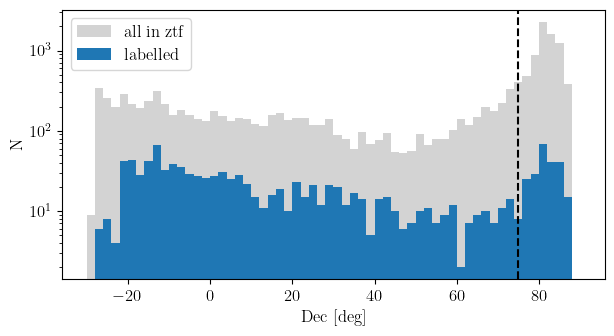

grp,unlabelled,trash,good,other
all,13719,688,326,165
dec < 75,6849,571,255,127


In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(-30, 90, 61)
ax.hist(ztf.dec, bins=bins, color='lightgray', label='all in ztf')
ax.hist(ztf.dec[ztf.grp != 'unlabelled'], bins=bins, color='C0', label='labelled')
ax.axvline(75, color='k', ls='--')
ax.set_xlabel('Dec [deg]'); ax.set_ylabel('N'); ax.legend(); ax.set_yscale('log')
plt.show()

cut1 = ztf.dec < 75
pd.DataFrame({'all': ztf.grp.value_counts(), 'dec < 75': ztf.grp[cut1].value_counts()}).T

Almost half of in\_ztf sits above dec 75°, where the trash notes say "PS1 images are bad quality" and we do not expect PS1 to detect anything. Only 2.5% of those sources were ever labelled, versus 9% below. Everything that follows uses dec < 75°.

## Cut 2: what separates trash from good?

Every ZTF detection carries the SEP shape measurements and the PSF-fit residuals. Ranking them by how much trash a one-sided cut removes while keeping 95% of good:

In [4]:
z = ztf[cut1].copy()
T, G, U = z.grp == 'trash', z.grp == 'good', z.grp == 'unlabelled'
f = lambda d, c: d[c].astype(float)

def band_features(d, b):
    det = d[f'ZTF_{b}_upper_lim_flag'] == 0
    kron = f(d, f'ZTF_{b}KronMag').where(f(d, f'ZTF_{b}KronMag') > -900)
    out = pd.DataFrame({
        'peak/flux': f(d, f'ZTF_{b}_peak') / f(d, f'ZTF_{b}_flux'),
        'size [pix]': np.sqrt((f(d, f'ZTF_{b}_x2') + f(d, f'ZTF_{b}_y2')) / 2),
        'tnpix': f(d, f'ZTF_{b}_tnpix'),
        'b/a': f(d, f'ZTF_{b}_b') / f(d, f'ZTF_{b}_a'),
        'PSF - Kron': f(d, f'ZTF_{b}PSFMag') - kron,
        'qfit': f(d, f'ZTF_{b}_qfit'),
        '|cfit|': f(d, f'ZTF_{b}_cfit').abs(),
        'S/N': f(d, f'ZTF_{b}_flux') / f(d, f'ZTF_{b}_thresh'),   # thresh = 1.0 x global rms
    }, index=d.index)
    out.loc[~det.values] = np.nan
    return out

feat = {b: band_features(z, b) for b in BANDS}

def rejection(t, g, keep=0.95):
    # Direction chosen by AUC; threshold = keep-quantile of good; returns fraction of trash beyond it.
    t, g = t.dropna(), g.dropna()
    auc = mannwhitneyu(t, g).statistic / (len(t) * len(g))
    thr = np.percentile(g, 100 * keep) if auc >= 0.5 else np.percentile(g, 100 * (1 - keep))
    return (t > thr).mean() if auc >= 0.5 else (t < thr).mean()

rows = []
for b in 'gr':
    for col in ['peak/flux', 'size [pix]', 'tnpix', 'b/a', 'PSF - Kron', 'qfit', '|cfit|']:
        v = feat[b][col]
        rows.append({'band': b, 'feature': col, 'median trash': v[T].median(), 'median good': v[G].median(),
                     'trash rejected (95% good kept)': rejection(v[T], v[G])})
pd.DataFrame(rows).sort_values('trash rejected (95% good kept)', ascending=False).round(3).reset_index(drop=True)

,band,feature,median trash,median good,trash rejected (95% good kept)
0,g,peak/flux,0.044,0.140,0.628
1,g,size [pix],2.212,1.156,0.577
2,r,peak/flux,0.057,0.150,0.561
3,g,tnpix,61.000,19.000,0.529
4,r,size [pix],1.920,1.148,0.509
5,r,tnpix,50.000,19.000,0.501
6,g,PSF - Kron,1.390,0.323,0.414
7,g,qfit,0.813,0.350,0.324
8,r,PSF - Kron,1.432,0.542,0.305
9,g,b/a,0.691,0.840,0.228


Trash is **resolved**: it has lower peak/flux, larger second moments, more pixels above threshold. The PSF-fit residuals (qfit, cfit) carry a weaker version of the same information and add nothing once shape is used (checked with a cross-validated classifier; shape alone and shape + fit metrics both plateau near 58% rejection at 95% retention). PSF − Kron is noisy on 1″ pixels; see the end of the notebook.

Peak/flux is the cleanest handle and has a first-principles meaning: **for a star, the brightest pixel holds a fixed fraction of the total light, set by the PSF.** Anything extended holds less.

## The stellar locus

Noise biases the peak upward for faint sources, so "too little light in the peak" must be judged against real stars at the same signal-to-noise. The in\_both catalog contains PS1-confirmed point sources (PS1 PSF − Kron within 0.05 mag) measured by the same extraction on the same images:

In [5]:
def reference_stars(both, b):
    psfk = f(both, f'PSTARR_{b}PSFMag') - f(both, f'PSTARR_{b}KronMag')
    m = ((both[f'ZTF_{b}_upper_lim_flag'] == 0) & (psfk.abs() < 0.05)
         & (f(both, f'ZTF_{b}_sepExtractionFlag') == 0) & (both.dec < 75))
    r = band_features(both[m], b)
    return r[np.isfinite(r['S/N']) & (r['S/N'] > 0) & np.isfinite(r['peak/flux'])]

def star_locus(ref, nbin=18):
    # Running median and lower 16th-percentile width of peak/flux in equal-count bins of log S/N.
    ls, v = np.log10(ref['S/N'].values), ref['peak/flux'].values
    edges = np.quantile(ls, np.linspace(0, 1, nbin + 1)); rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        q16, q50 = np.quantile(v[(ls >= lo) & (ls <= hi)], [0.16, 0.5])
        rows.append((0.5 * (lo + hi), q50, q50 - q16))
    return np.array(rows)

def point_source_z(feat_b, locus):
    # How many sigma the peak/flux sits BELOW the stellar value at this S/N. Large = resolved.
    ls = np.clip(np.log10(feat_b['S/N']), locus[0, 0], locus[-1, 0])
    med, sig = np.interp(ls, locus[:, 0], locus[:, 1]), np.interp(ls, locus[:, 0], locus[:, 2])
    return (med - feat_b['peak/flux']) / sig

stars = {b: reference_stars(both, b) for b in BANDS}
locus = {b: star_locus(stars[b]) for b in BANDS}
for b in BANDS:
    zz = point_source_z(stars[b], locus[b])
    print(f'{b}: {len(stars[b]):>6,} stars   fraction of stars beyond 3 sigma: {(zz > 3).mean():.4f}   beyond 4 sigma: {(zz > 4).mean():.4f}')

g: 24,265 stars   fraction of stars beyond 3 sigma: 0.0007   beyond 4 sigma: 0.0000
r: 18,528 stars   fraction of stars beyond 3 sigma: 0.0013   beyond 4 sigma: 0.0000
i: 16,096 stars   fraction of stars beyond 3 sigma: 0.0011   beyond 4 sigma: 0.0001


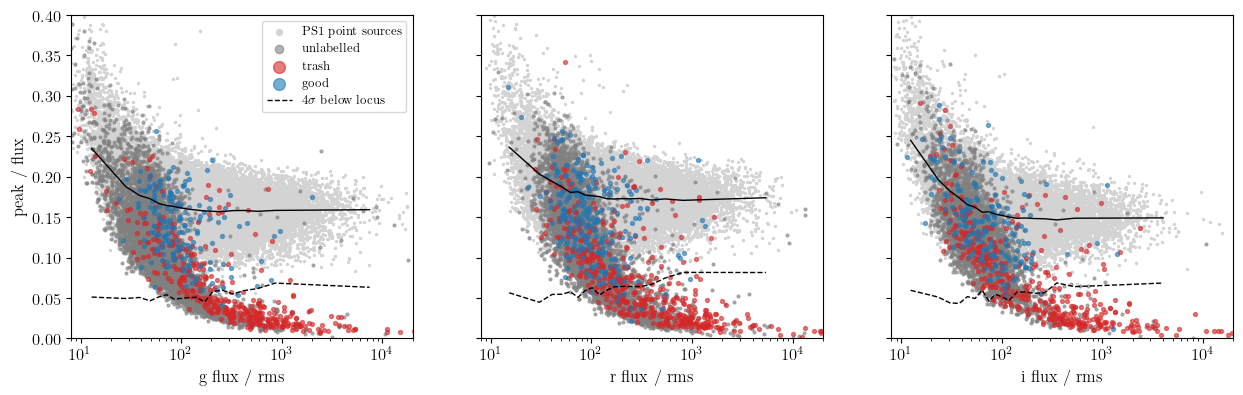

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, b in zip(axes, BANDS):
    s, L = stars[b], locus[b]
    ax.scatter(s['S/N'], s['peak/flux'], s=2, c='lightgray', label='PS1 point sources')
    for k, m, c, sz in [('unlabelled', U, 'gray', 4), ('trash', T, 'C3', 8), ('good', G, 'C0', 8)]:
        ax.scatter(feat[b]['S/N'][m], feat[b]['peak/flux'][m], s=sz, c=c, alpha=0.6, label=k)
    ax.plot(10**L[:, 0], L[:, 1], 'k-', lw=1)
    ax.plot(10**L[:, 0], L[:, 1] - 4 * L[:, 2], 'k--', lw=1, label=r'$4\sigma$ below locus')
    ax.set_xscale('log'); ax.set_xlim(8, 2e4); ax.set_ylim(0, 0.4)
    ax.set_xlabel(f'{b} flux / rms')
axes[0].set_ylabel('peak / flux'); axes[0].legend(fontsize=9, markerscale=3)
plt.show()

Stars sit on a flat locus (0.16–0.17 at high S/N, rising at the faint end). Trash sits on a second track where the peak is a few × rms whatever the total flux: the signature of diffuse emission (galaxy halos, outskirts, star halos). Good sources sit on the stellar locus.

## The filter and its performance

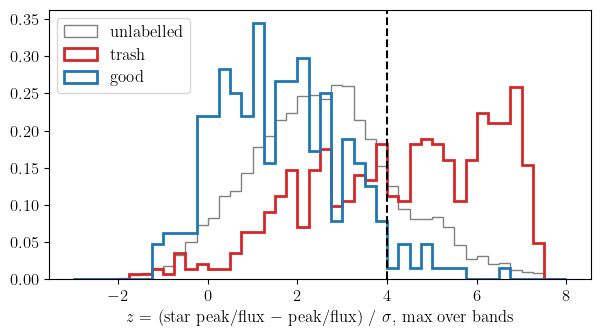

,trash rejected,good lost,unlabelled removed,Follow-up lost,TNS lost
z > 3.5,0.655,0.098,0.265,0.042,0.113
z > 4.0,0.576,0.047,0.179,0.042,0.038
z > 4.8,0.466,0.024,0.099,0.042,0.000


In [7]:
zpf = pd.DataFrame({b: point_source_z(feat[b], locus[b]) for b in BANDS})
z['zpf'] = zpf.max(axis=1)          # NaN if no band detected -> never cut
Z_CUT = 4.0

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(-3, 8, 45)
for k, m, c, lw in [('unlabelled', U, 'gray', 1), ('trash', T, 'C3', 2), ('good', G, 'C0', 2)]:
    ax.hist(z.zpf[m].clip(-3, 8).dropna(), bins=bins, density=True, histtype='step', color=c, lw=lw, label=k)
ax.axvline(Z_CUT, color='k', ls='--'); ax.set_xlabel(r'$z$ = (star peak/flux $-$ peak/flux) / $\sigma$, max over bands'); ax.legend()
plt.show()

def summary(cut, name):
    cut = cut.fillna(False)
    return pd.Series({'trash rejected': cut[T].mean(), 'good lost': cut[G].mean(), 'unlabelled removed': cut[U].mean(),
                      'Follow-up lost': cut[G & (has('Follow-up') | src.queued)[z.index]].mean(),
                      'TNS lost': cut[G & src.tns_matched.fillna(False).astype(bool)[z.index]].mean()}, name=name)

pd.DataFrame([summary(z.zpf > t, f'z > {t}') for t in [3.5, 4.0, 4.8]]).round(3)

At 4σ: 59% of trash, 5% of good, 18% of the unlabelled catalog. The cut acts only where shape is measurable: it leaves faint sources alone and removes most bright ones, which is right, since a bright source missing from PS1 is almost always a resolved object.

In [8]:
snr_bin = pd.cut(feat['r']['S/N'], [0, 30, 60, 120, 250, 500, np.inf])
cut = (z.zpf > Z_CUT).fillna(False)
pd.DataFrame({'N unlabelled': U.groupby(snr_bin, observed=False).sum(),
              'unlabelled removed': cut[U].groupby(snr_bin[U], observed=False).mean(),
              'trash removed': cut[T].groupby(snr_bin[T], observed=False).mean(),
              'good removed': cut[G].groupby(snr_bin[G], observed=False).mean()}).round(3)

,N unlabelled,unlabelled removed,trash removed,good removed
S/N,,,,
"(0.0, 30.0]",72,0.028,0.000,0.000
"(30.0, 60.0]",1636,0.010,0.000,0.000
"(60.0, 120.0]",3093,0.046,0.130,0.018
"(120.0, 250.0]",1155,0.414,0.505,0.089
"(250.0, 500.0]",407,0.862,0.779,0.250
"(500.0, inf]",191,0.853,0.948,0.250


## Alternatives, at matched good retention

Same labelled sample, each statistic thresholded to keep 95% of good. Includes the PS1 star/galaxy criterion (PSF − Kron) both raw and recalibrated on the ZTF-measured stars, and a cross-validated boosted-tree model on every shape feature as a ceiling.

In [9]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold

def psfkron_locus(ref, nbin=18):
    ls, v = np.log10(ref['S/N'].values), ref['PSF - Kron'].values; ok = np.isfinite(v); ls, v = ls[ok], v[ok]
    edges = np.quantile(ls, np.linspace(0, 1, nbin + 1)); rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        q50, q84 = np.quantile(v[(ls >= lo) & (ls <= hi)], [0.5, 0.84]); rows.append((0.5 * (lo + hi), q50, q84 - q50))
    return np.array(rows)

def psfkron_z(feat_b, L):
    ls = np.clip(np.log10(feat_b['S/N']), L[0, 0], L[-1, 0])
    return (feat_b['PSF - Kron'] - np.interp(ls, L[:, 0], L[:, 1])) / np.interp(ls, L[:, 0], L[:, 2])

shape_cols = ['peak/flux', 'size [pix]', 'tnpix', 'b/a']
X = pd.concat([feat[b][shape_cols + ['qfit', '|cfit|']].add_prefix(f'{b} ') for b in BANDS], axis=1)[T | G]
y = T[T | G].astype(int).values
p = cross_val_predict(HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200), X, y,
                      cv=StratifiedKFold(5, shuffle=True, random_state=0), method='predict_proba')[:, 1]
gbm = pd.Series(np.nan, index=z.index); gbm[T | G] = p

scores = {
    'peak/flux z-score, max over bands [proposed]': z.zpf,
    'raw peak/flux, min over bands (negated)': -pd.DataFrame({b: feat[b]['peak/flux'] for b in BANDS}).min(axis=1),
    'raw size, max over bands': pd.DataFrame({b: feat[b]['size [pix]'] for b in BANDS}).max(axis=1),
    'PSF - Kron, max over bands': pd.DataFrame({b: feat[b]['PSF - Kron'] for b in BANDS}).max(axis=1),
    'PSF - Kron z-score vs ZTF stars, max over bands': pd.DataFrame({b: psfkron_z(feat[b], psfkron_locus(stars[b])) for b in BANDS}).max(axis=1),
    'qfit, max over bands': pd.DataFrame({b: feat[b]['qfit'] for b in BANDS}).max(axis=1),
    'boosted trees on all shape + fit features (CV)': gbm,
}
rows = []
for name, s in scores.items():
    thr = np.nanpercentile(s[G], 95)
    rows.append(summary(s > thr, name))
pd.DataFrame(rows).round(3)

,trash rejected,good lost,unlabelled removed,Follow-up lost,TNS lost
"peak/flux z-score, max over bands [proposed]",0.592,0.051,0.189,0.042,0.047
"raw peak/flux, min over bands (negated)",0.604,0.051,0.204,0.042,0.047
"raw size, max over bands",0.545,0.051,0.160,0.042,0.028
"PSF - Kron, max over bands",0.319,0.051,0.119,0.042,0.028
"PSF - Kron z-score vs ZTF stars, max over bands",0.434,0.051,0.083,0.042,0.075
"qfit, max over bands",0.247,0.051,0.110,0.000,0.038
boosted trees on all shape + fit features (CV),0.590,0.051,0.000,0.042,0.028


Nothing beats the single peak/flux statistic, and the classifier confirms morphology plateaus near 60%.

**On PSF − Kron:** PS1's literal criterion (PSF − Kron > 0.05) would reject 71% of our good sources in r alone, because on a ZTF deep stack 30–40% of *genuine stars* at our candidates' S/N exceed 0.05 (2 pixel PSF, Kron radius barely measured, big aperture full of sky noise). Recalibrated it still trails peak/flux, since the Kron aperture is more sensitive to faint host light around a transient than the central pixel is.

## What the cut costs

In [10]:
lost = z[G & (z.zpf > Z_CUT)]
lost.assign(labels=lost.labels.apply(lambda L: ', '.join(sorted(L)) or 'TNS only'), z=lost.zpf.round(1))[
    ['coord_slug', 'labels', 'tns_name', 'tns_type', 'z']].reset_index(drop=True)

,coord_slug,labels,tns_name,tns_type,z
0,69p737101_n20p662240,Known Transient,SN2018ibb,SLSN-I,4.2
1,340p668546_n13p162320,Interesting?,<NA>,<NA>,5.6
2,52p048234_n0p186801,Interesting?,<NA>,<NA>,5.0
3,189p983985_n3p444164,Interesting?,<NA>,<NA>,4.3
4,117p419672_5p074109,Known Transient,SN2019smj,SN IIn,4.4
5,223p743335_2p993172,Follow-up,<NA>,<NA>,6.6
6,356p296127_5p799739,TNS only,AT2020ryv,<NA>,4.7
7,231p327960_30p505469,Interesting?,<NA>,<NA>,4.4
8,6p488807_39p450036,Interesting?,<NA>,<NA>,4.8
9,269p418109_50p038523,Known Transient,SN2018aye,SN Ia,4.8


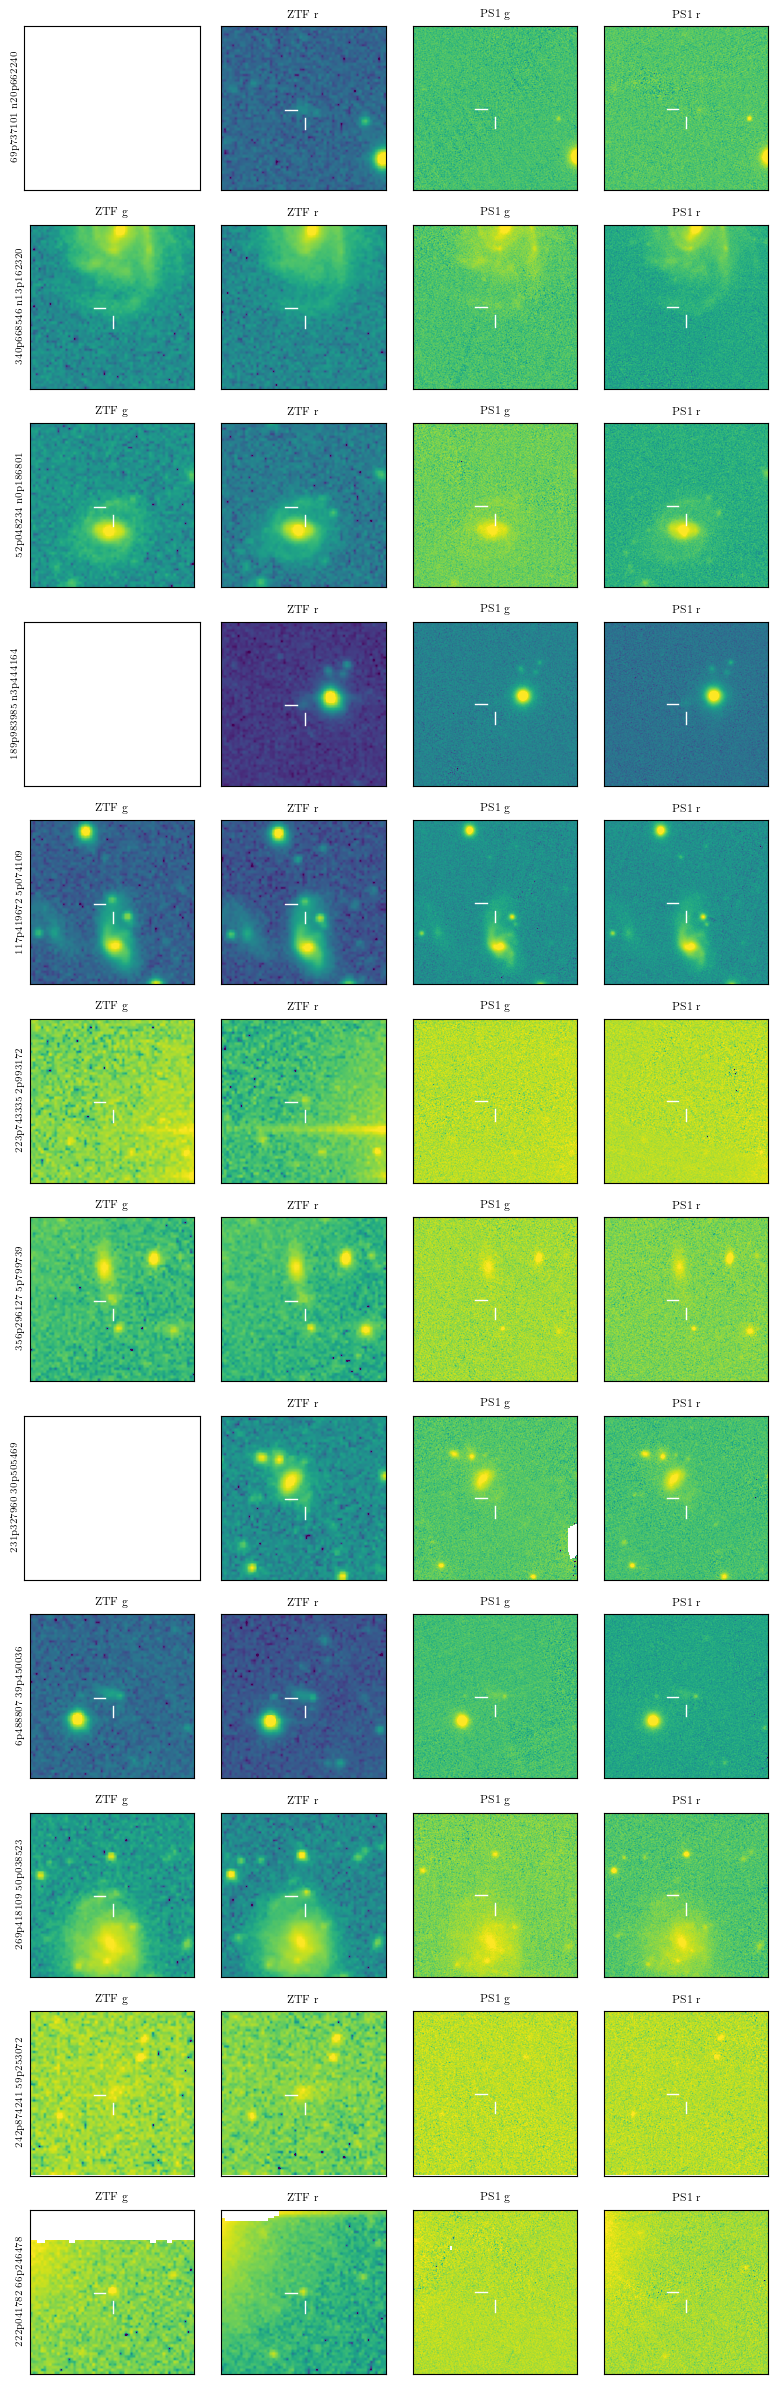

In [11]:
# 60" stamps of the good sources the cut removes (fetches from IRSA / PS1; ~30 s).
from concurrent.futures import ThreadPoolExecutor
from astropy.visualization import simple_norm
from source_db.cutouts import render

ps1_file = pd.read_sql('SELECT source_uuid, band, origin FROM cutout_sources WHERE survey="panstarrs"',
                       sqlite3.connect(f'{DB}/science.sqlite')).set_index(['source_uuid', 'band'])['origin'].to_dict()

def safe(fn, *a):
    try:
        return fn(*a)
    except Exception:          # transient 503s from IRSA / PS1: leave the panel blank
        return None

def fetch(r):
    out = {}
    for b in 'gr':
        out['ztf', b] = safe(render.fetch_ztf, r.fieldid, r.ccdid, r.qid, b, r.ra, r.dec)
        fn = ps1_file.get((r.source_uuid, b)); out['ps1', b] = safe(render.fetch_ps1, r.ra, r.dec, fn) if fn else None
    return out

with ThreadPoolExecutor(8) as ex:
    stamps = list(ex.map(fetch, [r for _, r in lost.iterrows()]))

fig, axes = plt.subplots(len(lost), 4, figsize=(8, 2 * len(lost)))
for ax_row, (_, r), imgs in zip(axes, lost.iterrows(), stamps):
    for ax, key in zip(ax_row, [('ztf', 'g'), ('ztf', 'r'), ('ps1', 'g'), ('ps1', 'r')]):
        ax.set_xticks([]); ax.set_yticks([]); img = imgs[key]
        if img is None:
            continue
        ax.imshow(img, origin='upper', cmap='viridis', norm=simple_norm(img, 'log', percent=99.5))
        n = img.shape[0]; ax.plot([0.38 * n, 0.45 * n], [n / 2] * 2, 'w-', lw=1); ax.plot([n / 2] * 2, [0.55 * n, 0.62 * n], 'w-', lw=1)
        ax.set_title(f'{key[0].upper()} {key[1]}', fontsize=8)
    ax_row[0].set_ylabel(r.coord_slug.replace('_', ' '), fontsize=7)
plt.tight_layout(); plt.show()

The losses are transients on visible hosts (SN2018aye, SN2019smj, SN2018ibb), knots in galaxy halos, and one bright star that is in the PS1 images but not its catalog. Raising the threshold to 4.8σ keeps all but 6 of these at the price of 13% less trash removed.

## The golden sample

In [12]:
cut2 = (ztf.index.to_series().map(z.zpf) > Z_CUT).fillna(False)
golden = ztf[cut1 & ~cut2]
print(f'in_ztf {len(ztf):,}  ->  dec < 75: {cut1.sum():,}  ->  point-source test: {len(golden):,}')
pd.DataFrame({'in_ztf': ztf.grp.value_counts(), 'golden': golden.grp.value_counts()}).T

in_ztf 14,898  ->  dec < 75: 7,802  ->  point-source test: 6,224


grp,good,other,trash,unlabelled
in_ztf,326,165,688,13719
golden,243,118,242,5621


Half of the surviving sources are fainter than S/N ≈ 120 in r, where no shape statistic can act. The remaining trash there is point-like ("steady source missing from PS1 catalog" in the notes, star-like WISE colors) and is a light-curve problem, not a morphology one.

---
# Building the sample, one cut at a time
Start from the raw in\_ztf table written by the pipeline and cut from the top down.

In [20]:
from Extracting.utils import load_ecsv

COMBINED = '/Users/adamboesky/Research/long_transients/Data/filter_results_final_10_22_2026/combined'
raw = load_ecsv(f'{COMBINED}/1_enriched.ecsv').to_pandas()
print(f'in_ztf raw: {len(raw):,}')

CasJobs will use the credentials from mast_dino_login.txt
in_ztf raw: 14,898


## Cut 1: dec < 75°
PS1 imaging is too poor near the pole for a PS1 non-detection to mean anything.

In [22]:
sample = raw[raw.dec < 75]
print(f'dec < 75: {len(sample):,}')

dec < 75: 7,802


## ZTF light curve: properties
Epochs from the ZTF DR24 light curves in `Data/db/light_curves`, matched to the sample by position. "Good" epochs are those passing the catflags mask from the ZTF Explanatory Supplement (10.3). Per-band statistics are quoted for the best-sampled band.

In [23]:
import pyarrow as pa, pyarrow.dataset as ds, pyarrow.compute as pc
from source_db.identity import coord_slugs

identity = pd.read_parquet(f'{DB}/identity.parquet').drop_duplicates('coord_slug').set_index('coord_slug')['source_uuid']
sample['source_uuid'] = identity.reindex(coord_slugs(sample.ra.values, sample.dec.values)).values

BAD_FLAGS = 6141 | 32768
lc = ds.dataset(f'{DB}/light_curves', format='parquet', partitioning='hive').to_table(
    columns=['source_uuid', 'band', 'mjd', 'mag', 'magerr', 'catflags'],
    filter=(pc.field('survey') == 'ztf') & pc.field('source_uuid').isin(pa.array(sample.source_uuid.dropna()))).to_pandas()
ok = lc[(lc.catflags.fillna(0).astype(int) & BAD_FLAGS) == 0]

def per_band(g):
    m, e = g.mag.values, g.magerr.values
    w = 1 / e**2; mu = np.sum(w * m) / np.sum(w)
    return pd.Series({'n': len(m), 'chi2_red': np.sum(w * (m - mu)**2) / max(len(m) - 1, 1), 'mag_range': m.max() - m.min(), 'mean_mag': mu})

band = ok.groupby(['source_uuid', 'band'])[['mag', 'magerr']].apply(per_band).reset_index()
best = band.sort_values('n', ascending=False).drop_duplicates('source_uuid').set_index('source_uuid')
by_src, by_src_ok = lc.groupby('source_uuid'), ok.groupby('source_uuid')
props = pd.DataFrame({
    'n_epochs': by_src.size(),
    'n_good': by_src_ok.size(),
    'n_nights': by_src_ok.mjd.apply(lambda m: np.unique(np.floor(m)).size),
    'span_days': by_src_ok.mjd.apply(lambda m: m.max() - m.min()),
}).join(ok.groupby(['source_uuid', 'band']).size().unstack(fill_value=0).reindex(columns=list('gri'), fill_value=0).add_prefix('n_good_')) \
  .join(best[['chi2_red', 'mag_range', 'mean_mag']].add_prefix('best_band_'))
props = props.reindex(sample.source_uuid.values); props.index = sample.index
count_cols = ['n_epochs', 'n_good', 'n_nights', 'span_days', 'n_good_g', 'n_good_r', 'n_good_i']
props[count_cols] = props[count_cols].fillna(0)
sample = sample.join(props)
sample[props.columns].describe().round(2).T

/var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/ipykernel_60311/986500797.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sample['source_uuid'] = identity.reindex(coord_slugs(sample.ra.values, sample.dec.values)).values


,count,mean,std,min,25%,50%,75%,max
n_epochs,7802.0,68.78,191.79,0.00,6.00,22.00,60.00,4531.00
n_good,7802.0,64.44,179.33,0.00,5.00,21.00,57.00,4185.00
n_nights,7802.0,44.45,78.83,0.00,5.00,19.00,50.00,1117.00
span_days,7802.0,1774.14,963.25,0.00,1147.87,2210.00,2575.89,2771.23
n_good_g,7802.0,15.74,64.54,0.00,0.00,1.00,10.00,1734.00
n_good_r,7802.0,42.42,109.74,0.00,1.00,13.00,39.00,1910.00
n_good_i,7802.0,6.27,21.39,0.00,0.00,0.00,4.00,541.00
best_band_chi2_red,6892.0,5.98,30.40,0.00,1.37,2.22,3.92,1374.66
best_band_mag_range,6892.0,1.24,0.63,0.00,0.87,1.27,1.61,5.69
best_band_mean_mag,6892.0,20.83,0.74,13.45,20.72,20.99,21.19,22.11


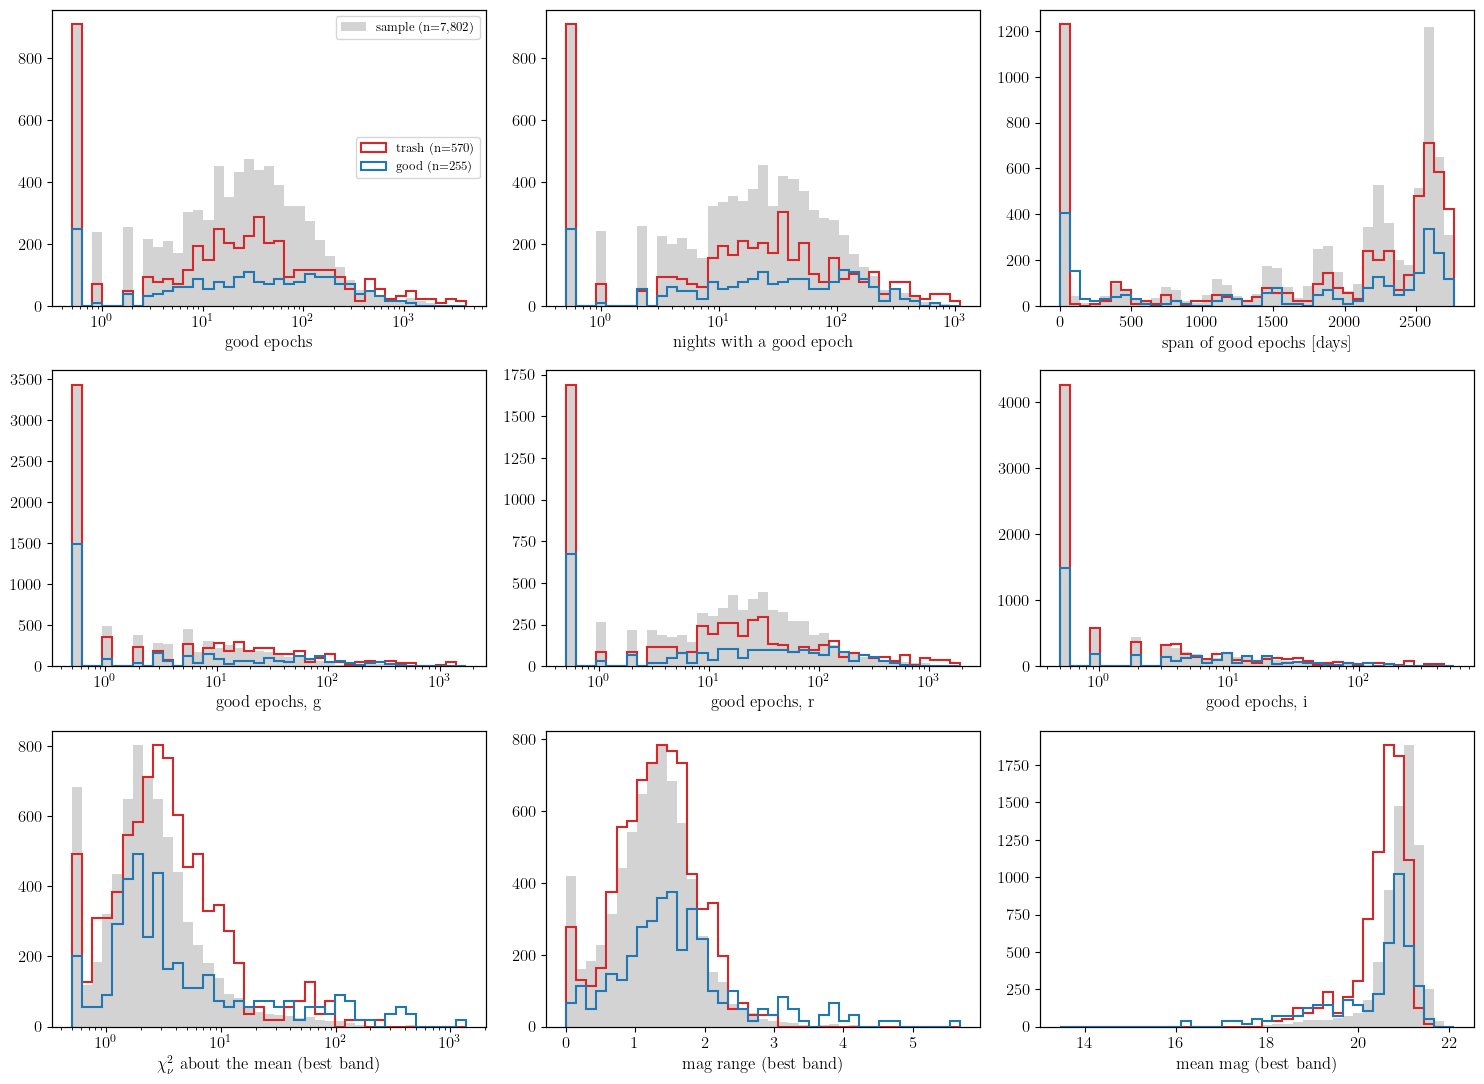

In [24]:
grp = sample.source_uuid.map(src.set_index('source_uuid').grp).fillna('unlabelled')
panels = [('n_good', 'good epochs', 'log'), ('n_nights', 'nights with a good epoch', 'log'), ('span_days', 'span of good epochs [days]', 'lin'),
          ('n_good_g', 'good epochs, g', 'log'), ('n_good_r', 'good epochs, r', 'log'), ('n_good_i', 'good epochs, i', 'log'),
          ('best_band_chi2_red', r'$\chi^2_\nu$ about the mean (best band)', 'log'), ('best_band_mag_range', 'mag range (best band)', 'lin'), ('best_band_mean_mag', 'mean mag (best band)', 'lin')]
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, (col, label, scale) in zip(axes.flat, panels):
    v = sample[col].dropna()
    if scale == 'log':
        v = v.clip(lower=0.5); bins = np.logspace(np.log10(0.5), np.log10(v.max()), 40); ax.set_xscale('log')
    else:
        bins = np.linspace(v.min(), v.max(), 40)
    ax.hist(v, bins=bins, color='lightgray', label=f'sample (n={len(v):,})')
    ax2 = ax.twinx()
    for k, c in [('trash', 'C3'), ('good', 'C0')]:
        vv = sample.loc[grp == k, col].dropna(); vv = vv.clip(lower=0.5) if scale == 'log' else vv
        ax2.hist(vv, bins=bins, histtype='step', lw=1.5, color=c, label=f'{k} (n={len(vv)})')
    ax2.set_yticks([]); ax.set_xlabel(label)
    if col == 'n_good': ax.legend(loc='upper right', fontsize=9); ax2.legend(loc='center right', fontsize=9)
plt.tight_layout(); plt.show()

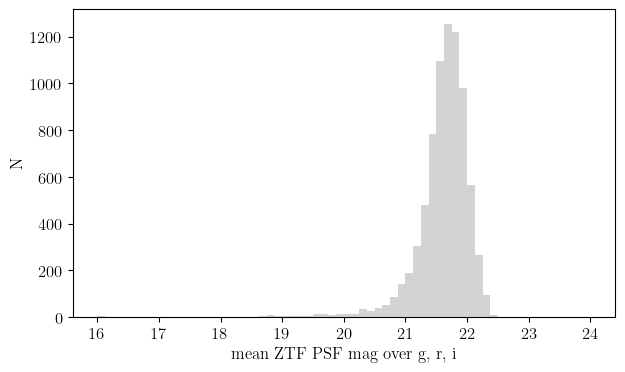

In [28]:
psf = sample[[f'ZTF_{b}PSFMag' for b in 'gri']].astype(float)
sample['mean_psf_mag'] = psf.mean(axis=1)          # mean over the detected bands

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(sample.mean_psf_mag.dropna(), bins=np.linspace(16, 24, 65), color='lightgray')
ax.set_xlabel('mean ZTF PSF mag over g, r, i'); ax.set_ylabel('N')
plt.show()

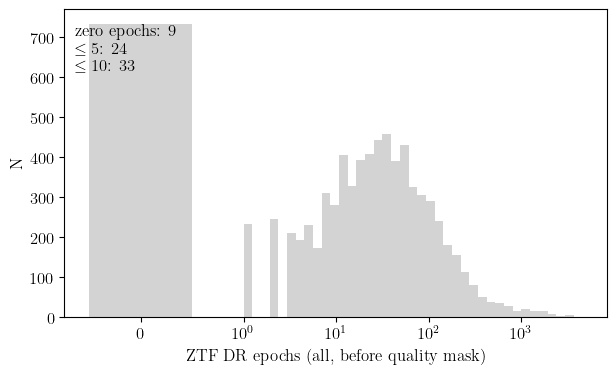

In [29]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.concatenate([[-0.5, 0.5], np.logspace(0, np.log10(sample.n_epochs.max()), 40)])
ax.hist(sample.n_epochs, bins=bins, color='lightgray')
ax.set_xscale('symlog', linthresh=1); ax.set_xlabel('ZTF DR epochs (all, before quality mask)'); ax.set_ylabel('N')
ax.text(0.02, 0.95, f'zero epochs: {(sample.n_epochs == 0).mean():.0%}' + '\n' + rf'$\leq 5$: {(sample.n_epochs <= 5).mean():.0%}' + '\n' + rf'$\leq 10$: {(sample.n_epochs <= 10).mean():.0%}',
        transform=ax.transAxes, va='top')
plt.show()

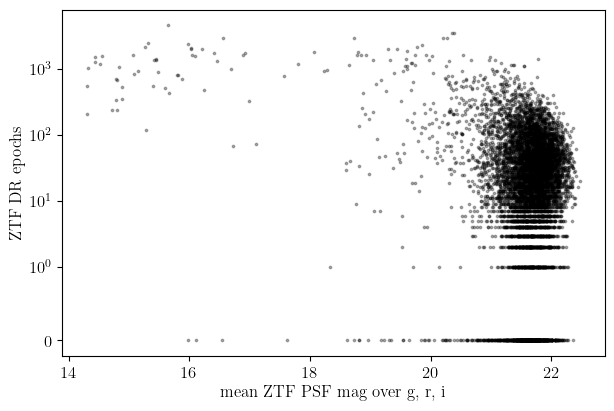

In [32]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(sample.mean_psf_mag, sample.n_epochs, s=3, c='k', alpha=0.3)
ax.set_yscale('symlog', linthresh=1)
ax.set_xlabel('mean ZTF PSF mag over g, r, i'); ax.set_ylabel('ZTF DR epochs')
plt.show()

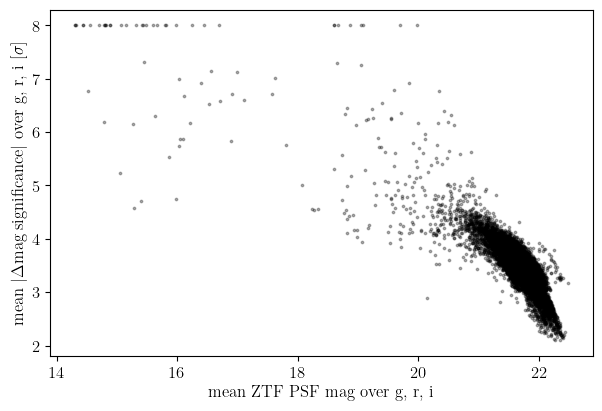

In [ ]:
sample['mean_abs_dmag_sigma'] = sample[[f'{b}_dmag_sigma' for b in 'gri']].astype(float).abs().mean(axis=1)   # mean over the detected bands

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(sample.mean_psf_mag, sample.mean_abs_dmag_sigma, s=3, c='k', alpha=0.3)
ax.set_xlabel('mean ZTF PSF mag over g, r, i'); ax.set_ylabel(r'mean $|\Delta$mag significance$|$ over g, r, i [$\sigma$]')
plt.show()

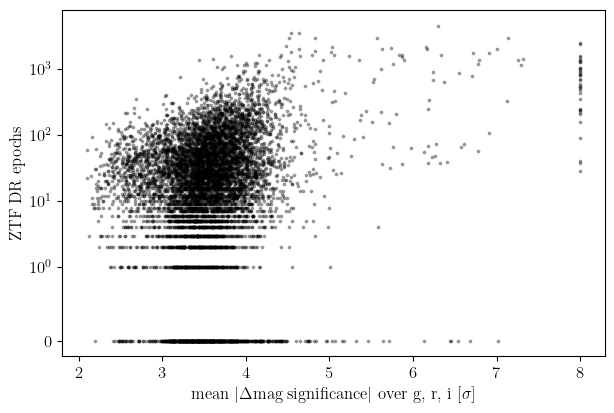

In [37]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(sample.mean_abs_dmag_sigma, sample.n_epochs, s=3, c='k', alpha=0.3)
ax.set_yscale('symlog', linthresh=1)
ax.set_xlabel(r'mean $|\Delta$mag significance$|$ over g, r, i [$\sigma$]'); ax.set_ylabel('ZTF DR epochs')
plt.show()

985 / 7802 objects with WISE colors


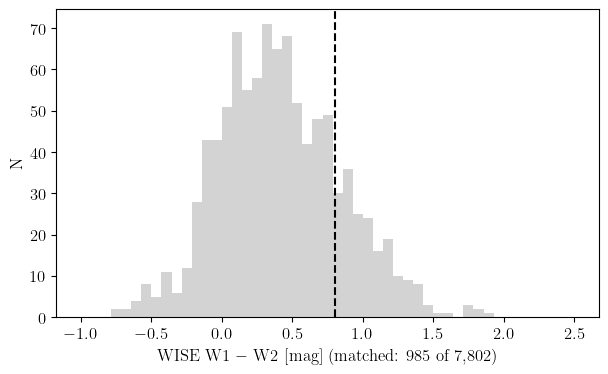

In [39]:
w1w2 = sample.wise_w1w2.astype(float).dropna()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(w1w2, bins=np.linspace(-1, 2.5, 50), color='lightgray')
ax.axvline(0.8, color='k', ls='--')
ax.set_xlabel(f'WISE W1 $-$ W2 [mag]   (matched: {len(w1w2):,} of {len(sample):,})'); ax.set_ylabel('N')
print(f'{len(w1w2)} / {len(sample)} objects with WISE colors')
plt.show()

## ZTF light curve: correlation statistics
Do consecutive epochs move together (smooth evolution) or independently (noise)? Computed on nightly means in the best-sampled band, for sources with at least 10 nights. Von Neumann ratio: ~2 for white noise, small for a trend. Stetson J: positive when consecutive residuals share a sign. Stetson K: 0.80 for Gaussian scatter, lower when one outlier dominates. Spearman: rank correlation of magnitude with time, so $|\rho| \to 1$ for a monotonic rise or decline.

In [40]:
from scipy.stats import spearmanr

MIN_NIGHTS = 10

def nightly(g):
    # inverse-variance mean per night, in the source's best-sampled band
    w = 1 / g.magerr**2
    night = np.floor(g.mjd)
    out = pd.DataFrame({'mjd': g.mjd.groupby(night).mean(), 'mag': (g.mag * w).groupby(night).sum() / w.groupby(night).sum(),
                        'magerr': 1 / np.sqrt(w.groupby(night).sum())})
    return out.reset_index(drop=True).sort_values('mjd')

def correlation_stats(g):
    g = nightly(g); t, m, e = g.mjd.values, g.mag.values, g.magerr.values; N = len(m)
    if N < MIN_NIGHTS:
        return pd.Series(dtype=float)
    var = m.var(ddof=1); dm, dt = np.diff(m), np.diff(t)
    delta = np.sqrt(N / (N - 1)) * (m - m.mean()) / e           # Stetson 1996 normalised residuals
    P = delta[:-1] * delta[1:]                                   # consecutive-night pairs
    return pd.Series({
        'von_neumann': np.sum(dm**2) / ((N - 1) * var),                                     # ~2 white noise, small = smooth
        'von_neumann_e': (t[-1] - t[0])**2 / (N - 1)**3 * np.sum((dm / dt)**2) / var,      # uneven-sampling form (Kim+2014; Malanchev+2021)
        'stetson_J': np.sum(np.sign(P) * np.sqrt(np.abs(P))) / len(P),                       # >0 correlated consecutive residuals
        'stetson_K': np.mean(np.abs(delta)) / np.sqrt(np.mean(delta**2)),                    # 0.80 Gaussian, ->0 single outlier
        'spearman_t': spearmanr(t, m).statistic,                                             # monotonic trend; + = fading
        'n_nights_used': N,
    })

best_band = ok.groupby(['source_uuid', 'band']).size().reset_index(name='n').sort_values('n', ascending=False).drop_duplicates('source_uuid').set_index('source_uuid').band
corr = ok[ok.band == ok.source_uuid.map(best_band)].groupby('source_uuid')[['mjd', 'mag', 'magerr']].apply(correlation_stats)
corr = corr.unstack() if isinstance(corr.index, pd.MultiIndex) else corr
corr = corr.reindex(sample.source_uuid.values); corr.index = sample.index
sample = sample.join(corr)
print(f'defined for {corr.von_neumann.notna().sum():,} of {len(sample):,} sources (>= {MIN_NIGHTS} nights in the best band)')
sample[corr.columns].describe().round(3).T

defined for 4,707 of 7,802 sources (>= 10 nights in the best band)


,count,mean,std,min,25%,50%,75%,max
n_nights_used,4707.0,54.592,73.493,10.000,18.000,30.000,60.000,901.000
spearman_t,4707.0,-0.046,0.245,-0.921,-0.193,-0.044,0.100,0.999
stetson_J,4707.0,0.216,1.798,-6.294,-0.074,0.106,0.273,79.558
stetson_K,4707.0,0.708,0.100,0.131,0.659,0.721,0.772,0.973
von_neumann,4707.0,1.780,0.446,0.020,1.513,1.769,2.051,3.554
von_neumann_e,4707.0,700.635,2149.142,0.031,91.486,209.989,550.268,54790.710


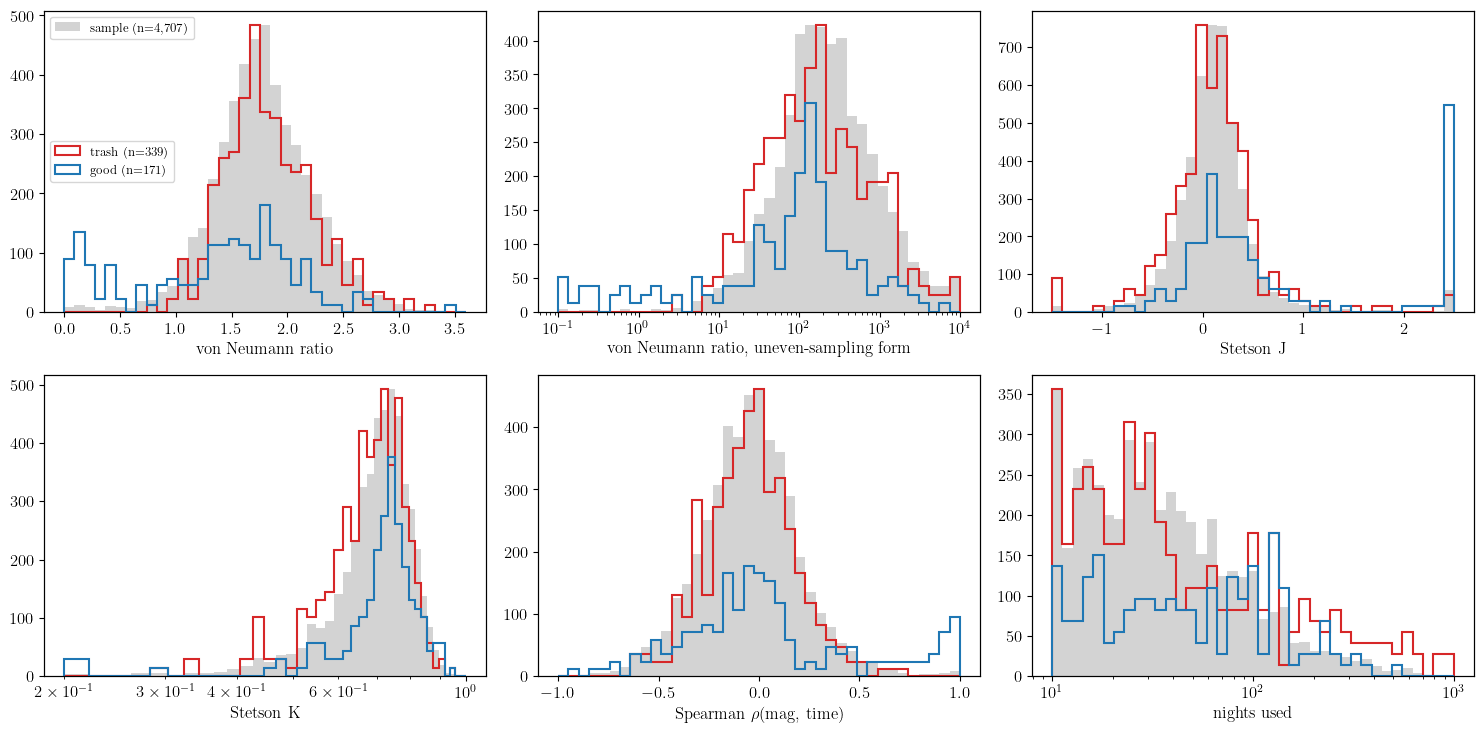

In [41]:
grp = sample.source_uuid.map(src.set_index('source_uuid').grp).fillna('unlabelled')
panels = [('von_neumann', 'von Neumann ratio', np.linspace(0, 3.6, 40)),
          ('von_neumann_e', 'von Neumann ratio, uneven-sampling form', np.logspace(-1, 4, 40)),
          ('stetson_J', 'Stetson J', np.linspace(-1.5, 2.5, 40)),
          ('stetson_K', 'Stetson K', np.linspace(0.2, 1.0, 40)),
          ('spearman_t', r'Spearman $\rho$(mag, time)', np.linspace(-1, 1, 40)),
          ('n_nights_used', 'nights used', np.logspace(1, 3, 40))]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, (col, label, bins) in zip(axes.flat, panels):
    v = sample[col].dropna().clip(bins[0], bins[-1])
    ax.hist(v, bins=bins, color='lightgray', label=f'sample (n={len(v):,})')
    ax2 = ax.twinx()
    for k, c in [('trash', 'C3'), ('good', 'C0')]:
        vv = sample.loc[grp == k, col].dropna().clip(bins[0], bins[-1])
        ax2.hist(vv, bins=bins, histtype='step', lw=1.5, color=c, label=f'{k} (n={len(vv)})')
    ax2.set_yticks([]); ax.set_xlabel(label)
    if bins[0] > 0 and bins[1] / bins[0] > 1.05: ax.set_xscale('log')
    if col == 'von_neumann': ax.legend(loc='upper left', fontsize=9); ax2.legend(loc='center left', fontsize=9)
plt.tight_layout(); plt.show()

## Cut 2: light-curve sampling
Survivors for a floor on epoch count, counting ZTF good epochs alone and ZTF plus PS1 single-epoch detections (the PS1 detections table, 2009–2015). The cut applied below uses ZTF alone, since every light-curve statistic above is ZTF-based.

In [42]:
ps1 = ds.dataset(f'{DB}/light_curves', format='parquet', partitioning='hive').to_table(
    columns=['source_uuid', 'mjd'], filter=(pc.field('survey') == 'panstarrs') & pc.field('source_uuid').isin(pa.array(sample.source_uuid.dropna()))).to_pandas()
n_ps1 = ps1.groupby('source_uuid').size().reindex(sample.source_uuid.values).fillna(0).values
sample['n_epochs_ps1'] = n_ps1
sample['n_epochs_with_ps1'] = sample.n_good + sample.n_epochs_ps1

print(f'sources with any PS1 epochs: {(sample.n_epochs_ps1 > 0).sum():,}')
pd.DataFrame({f'>= {n}': {'ZTF good epochs': (sample.n_good >= n).sum(), 'ZTF good + PS1 epochs': (sample.n_epochs_with_ps1 >= n).sum()} for n in [5, 10, 20, 50]})

sources with any PS1 epochs: 5,206


,>= 5,>= 10,>= 20,>= 50
ZTF good epochs,5995,5166,4001,2214
ZTF good + PS1 epochs,6315,5477,4220,2337


ZTF good epochs >= 10: 5,166


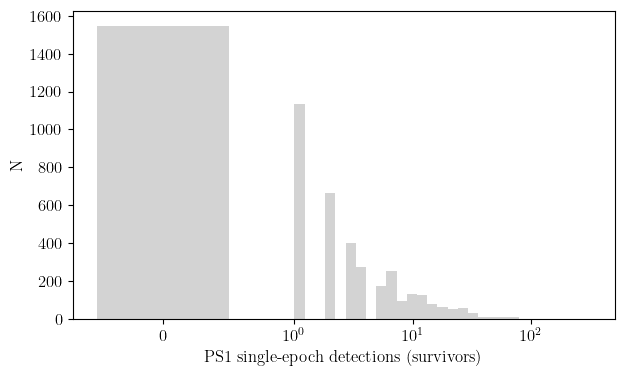

In [43]:
MIN_EPOCHS = 10
sample = sample[sample.n_good >= MIN_EPOCHS]
print(f'ZTF good epochs >= {MIN_EPOCHS}: {len(sample):,}')

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.concatenate([[-0.5, 0.5], np.logspace(0, 2.5, 30)])
ax.hist(sample.n_epochs_ps1, bins=bins, color='lightgray')
ax.set_xscale('symlog', linthresh=1); ax.set_xlabel('PS1 single-epoch detections (survivors)'); ax.set_ylabel('N')
plt.show()

## Looking at the best objects
Pairs of light-curve metrics for the survivors. TNS matches are marked for reference only. The table ranks sources by the sum of ranks over the metrics in `RANK_ON` (edit the list), so a source has to score on all of them to come out on top.

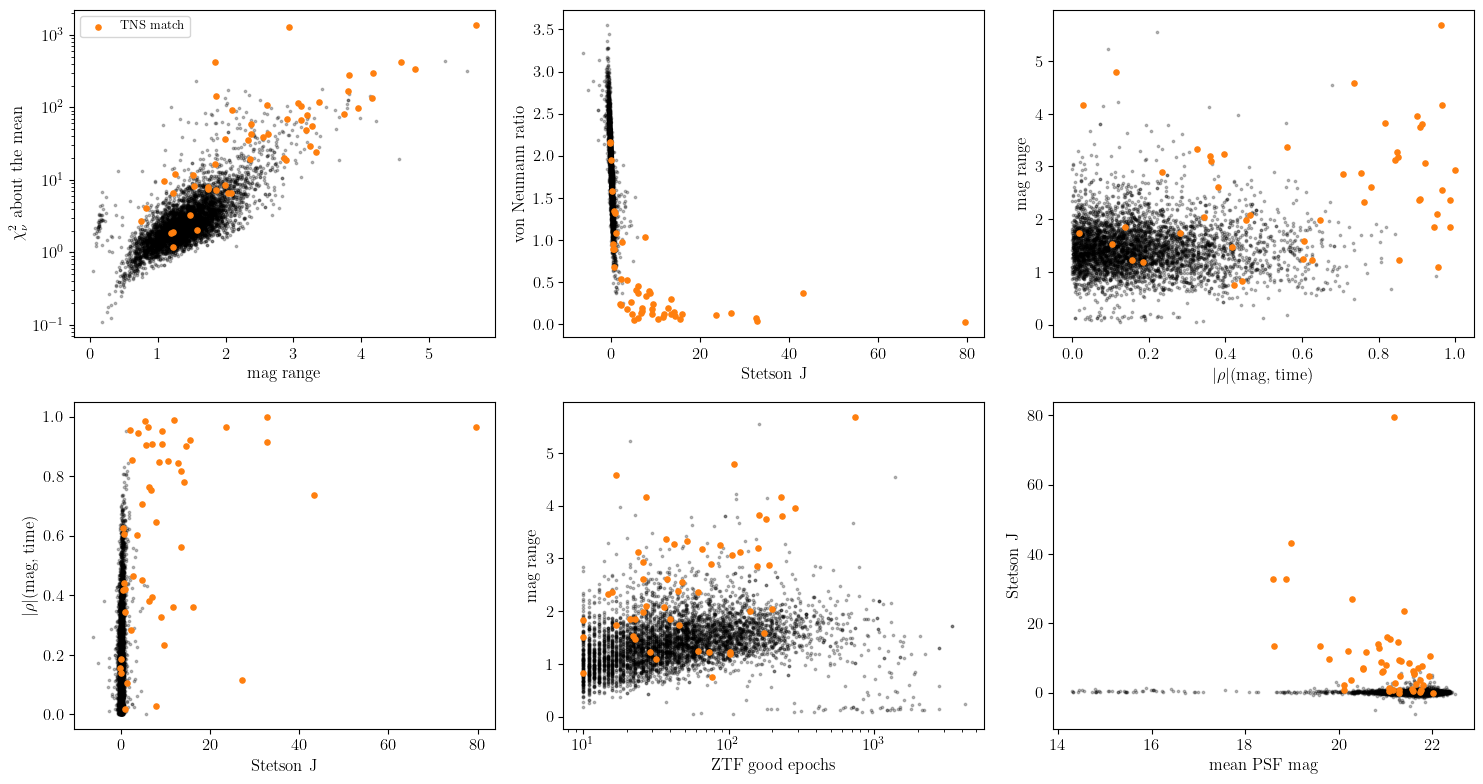

In [44]:
sample['abs_spearman'] = sample.spearman_t.abs()
tns = sample.tns_matched.fillna(False).astype(bool)
pairs = [('best_band_mag_range', 'best_band_chi2_red'), ('stetson_J', 'von_neumann'),
         ('abs_spearman', 'best_band_mag_range'), ('stetson_J', 'abs_spearman'),
         ('n_good', 'best_band_mag_range'), ('mean_psf_mag', 'stetson_J')]
labels = {'best_band_mag_range': 'mag range', 'best_band_chi2_red': r'$\chi^2_\nu$ about the mean', 'stetson_J': 'Stetson J',
          'von_neumann': 'von Neumann ratio', 'abs_spearman': r'$|\rho|$(mag, time)', 'n_good': 'ZTF good epochs', 'mean_psf_mag': 'mean PSF mag'}
logs = {'best_band_chi2_red', 'n_good'}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (x, y) in zip(axes.flat, pairs):
    ax.scatter(sample[x], sample[y], s=3, c='k', alpha=0.25)
    ax.scatter(sample.loc[tns, x], sample.loc[tns, y], s=14, c='C1', label='TNS match')
    if x in logs: ax.set_xscale('log')
    if y in logs: ax.set_yscale('log')
    ax.set_xlabel(labels[x]); ax.set_ylabel(labels[y])
axes.flat[0].legend(fontsize=9)
plt.tight_layout(); plt.show()

In [46]:
RANK_ON = {'best_band_mag_range': 'high', 'best_band_chi2_red': 'high', 'stetson_J': 'high', 'abs_spearman': 'high', 'von_neumann': 'low'}
N_TOP = 25

sample['coord_slug'] = coord_slugs(sample.ra.values, sample.dec.values)
ranks = pd.DataFrame({c: sample[c].rank(ascending=(d == 'low')) for c, d in RANK_ON.items()})
sample['rank_score'] = ranks.mean(axis=1)
top = sample.nsmallest(N_TOP, 'rank_score')
top[['coord_slug', 'ra', 'dec', 'mean_psf_mag', 'n_good', 'best_band_mag_range', 'best_band_chi2_red', 'stetson_J', 'von_neumann', 'spearman_t', 'tns_name', 'tns_type']].round(2).reset_index(drop=True)

,coord_slug,ra,dec,mean_psf_mag,n_good,best_band_mag_range,best_band_chi2_red,stetson_J,von_neumann,spearman_t,tns_name,tns_type
0,269p418109_50p038523,269.42,50.04,21.17,741.0,5.69,1374.66,79.56,0.02,0.96,SN2018aye,SN Ia
1,150p277754_54p789437,150.28,54.79,21.40,27.0,4.17,299.09,23.65,0.11,0.96,SN2020aczg,SN Ia
2,59p544614_n8p816938,59.54,-8.82,18.86,231.0,3.81,165.82,32.71,0.07,0.91,SN2020svn,SN II
3,177p671775_n10p227470,177.67,-10.23,18.60,26.0,2.93,1303.29,32.73,0.03,1.00,SN2020acat,SN IIb
4,117p419672_5p074109,117.42,5.07,19.60,161.0,3.82,275.90,13.53,0.12,0.82,SN2019smj,SN IIn
5,203p811182_44p766277,203.81,44.77,18.98,17.0,4.59,422.73,43.22,0.37,0.74,SN2019va,SN IIP
6,30p128656_37p050839,30.13,37.05,21.26,286.0,3.96,98.31,14.49,0.10,0.90,SN2019khb,SN II
7,359p324698_n15p631571,359.32,-15.63,21.10,105.0,3.06,115.02,15.56,0.06,-0.92,SN2018gft,SLSN-I
8,130p748491_59p567875,130.75,59.57,21.32,181.0,3.74,80.26,9.18,0.12,0.91,SN2019bjr,SN IIP
9,218p540031_12p722269,218.54,12.72,20.85,24.0,3.12,104.32,12.89,0.20,0.84,SN2021emc,SN Ia


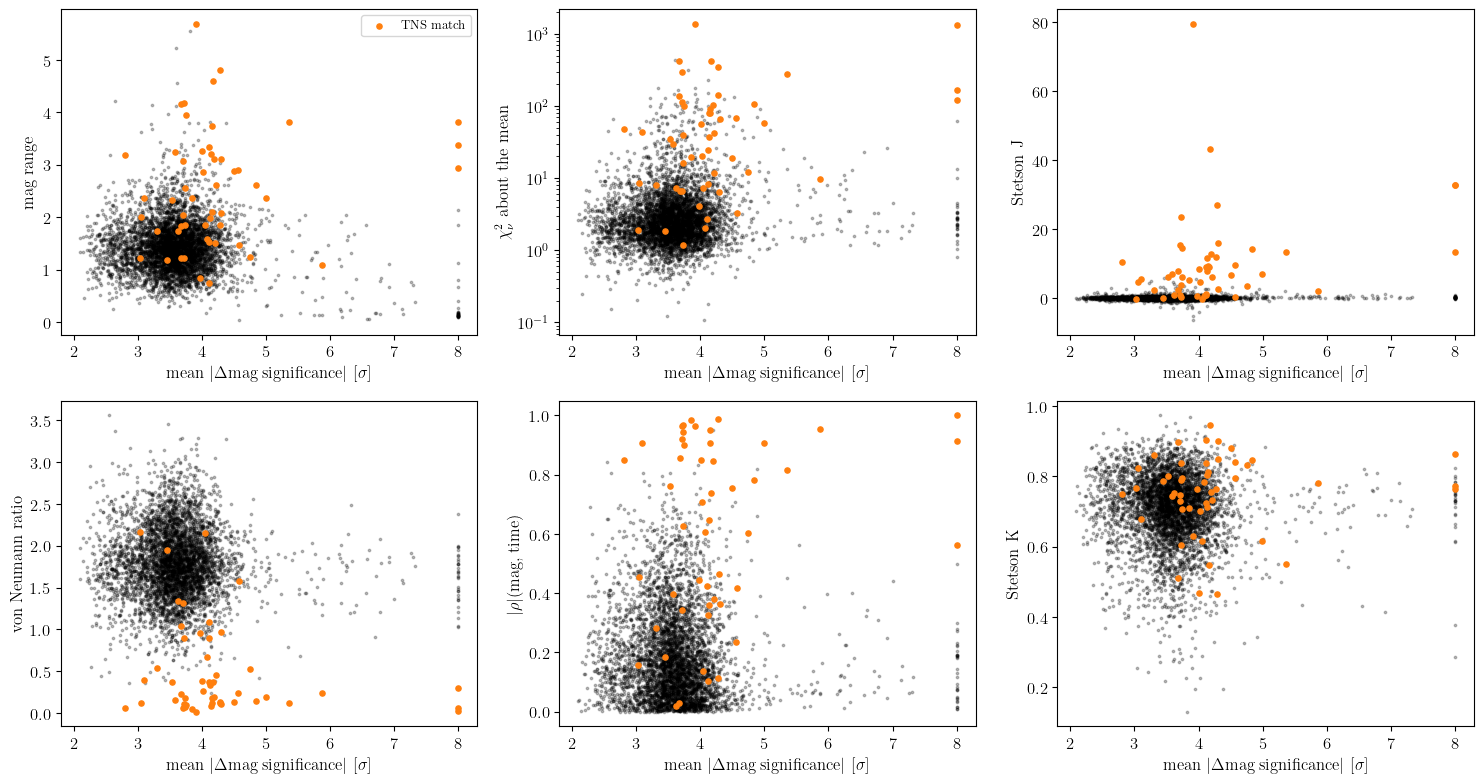

In [47]:
metrics = ['best_band_mag_range', 'best_band_chi2_red', 'stetson_J', 'von_neumann', 'abs_spearman', 'stetson_K']
labels['stetson_K'] = 'Stetson K'
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, m in zip(axes.flat, metrics):
    ax.scatter(sample.mean_abs_dmag_sigma, sample[m], s=3, c='k', alpha=0.25)
    ax.scatter(sample.loc[tns, 'mean_abs_dmag_sigma'], sample.loc[tns, m], s=14, c='C1', label='TNS match')
    if m in logs: ax.set_yscale('log')
    ax.set_xlabel(r'mean $|\Delta$mag significance$|$ [$\sigma$]'); ax.set_ylabel(labels[m])
axes.flat[0].legend(fontsize=9)
plt.tight_layout(); plt.show()

## Do neighbouring points move the same way?
The criterion is local and shape-free: consecutive nightly steps should share a direction, whether the source is rising, falling, or both, and whatever came before. Nights are taken in the order observed; the cadence itself decides what "neighbouring" means, with no cut on the gap between them.

- `diff_acf1`: uncentred lag-one autocorrelation of the nightly steps (each step times the next, summed, normalised). Pure noise about a constant gives $-0.5$ (a step up is followed by a step back); same-direction steps give $+1$. Over the whole light curve, so a long flat stretch dilutes it.
- `diff_acf1_max`: the same over a sliding window of 8 step pairs, keeping the best, so a coherent stretch anywhere counts. Noise alone reaches ~0.3 at the 90th percentile of its maximum, so read it with `run_sigma`.
- `same_sign`: the fraction of consecutive step pairs that agree in direction. Only the signs enter, so every pair counts the same whatever its amplitude or spacing. Noise gives $1/3$ exactly; a coherent run gives 1.
- `longest_run` and `run_sigma`: nights in the longest run of same-direction steps (a step under half its error neither breaks nor turns it), and the net change across it in units of its error. Noise gives ~2σ.

Checked on synthetic light curves (40 nights, same cadence): noise $\to$ acf1 $-0.50$, same-sign 0.39, run 1.8σ; a steady rise $\to$ $+0.41$, 0.78, 106σ; a Gaussian rise-and-fall $\to$ $+0.03$ (diluted by its flat wings) but windowed $+0.56$, same-sign 0.58, run 17σ.

In [48]:
MIN_PAIRS = 8          # pairs of consecutive steps needed to quote the statistics
WINDOW_PAIRS = 8       # sliding window for the local version

def direction_stats(g):
    g = nightly(g); t, m, e = g.mjd.values, g.mag.values, g.magerr.values
    d = np.diff(m)                                            # nightly steps, in the order observed
    e_d = np.sqrt(e[1:]**2 + e[:-1]**2)
    if len(d) - 1 < MIN_PAIRS:
        return pd.Series(dtype=float)
    a, b = d[:-1], d[1:]                                      # each step and the one after it
    acf = lambda x, y: np.sum(x * y) / np.sqrt(np.sum(x**2) * np.sum(y**2))
    acf1 = acf(a, b)                                          # uncentred: +1 same-direction steps, -0.5 pure noise
    # The same over a sliding window of WINDOW_PAIRS, keeping the best: a coherent
    # stretch anywhere counts, whatever the rest of the light curve does.
    acf1_max = max(acf(a[i:i + WINDOW_PAIRS], b[i:i + WINDOW_PAIRS])
                   for i in range(0, max(1, len(a) - WINDOW_PAIRS + 1)))
    same_sign = np.mean(np.sign(a) == np.sign(b))             # amplitude-free: 1/3 for noise, 1 for a coherent run
    # Longest run of same-direction steps, where a step smaller than half its error
    # neither breaks nor turns the run. `run_sigma` is the net change over it.
    sign = np.sign(d) * (np.abs(d) > 0.5 * e_d)
    best_len, best_sig, start, cur = 0, 0.0, 0, 0
    for i in range(len(d)):
        if sign[i] == 0 or cur == 0 or sign[i] == cur:
            if sign[i] != 0: cur = sign[i]
        else:
            start, cur = i, sign[i]
        length = i + 1 - start
        if length > best_len:
            best_len = length
            best_sig = abs(m[i + 1] - m[start]) / np.sqrt(e[i + 1]**2 + e[start]**2)
    return pd.Series({'diff_acf1': acf1, 'diff_acf1_max': acf1_max, 'same_sign': same_sign,
                      'n_pairs': len(a), 'longest_run': best_len, 'run_sigma': best_sig})

direction = ok[ok.band == ok.source_uuid.map(best_band)].groupby('source_uuid')[['mjd', 'mag', 'magerr']].apply(direction_stats)
direction = direction.unstack() if isinstance(direction.index, pd.MultiIndex) else direction
direction = direction.reindex(sample.source_uuid.values); direction.index = sample.index
sample = sample.join(direction)
print(f'defined for {direction.diff_acf1.notna().sum():,} of {len(sample):,} sources (>= {MIN_PAIRS} step pairs)')
sample[direction.columns].describe().round(3).T

defined for 3,234 of 5,166 sources (>= 8 step pairs within 60 d)


,count,mean,std,min,25%,50%,75%,max
diff_acf1,3234.0,-0.430,0.179,-0.906,-0.533,-0.451,-0.352,0.650
diff_acf1_max,3234.0,0.030,0.342,-0.903,-0.216,0.067,0.279,0.974
longest_run,3234.0,5.487,2.583,1.000,4.000,5.000,7.000,52.000
n_pairs,3234.0,56.890,81.941,8.000,15.000,29.000,63.000,893.000
run_sigma,3234.0,2.260,2.596,0.002,1.102,1.756,2.686,65.299


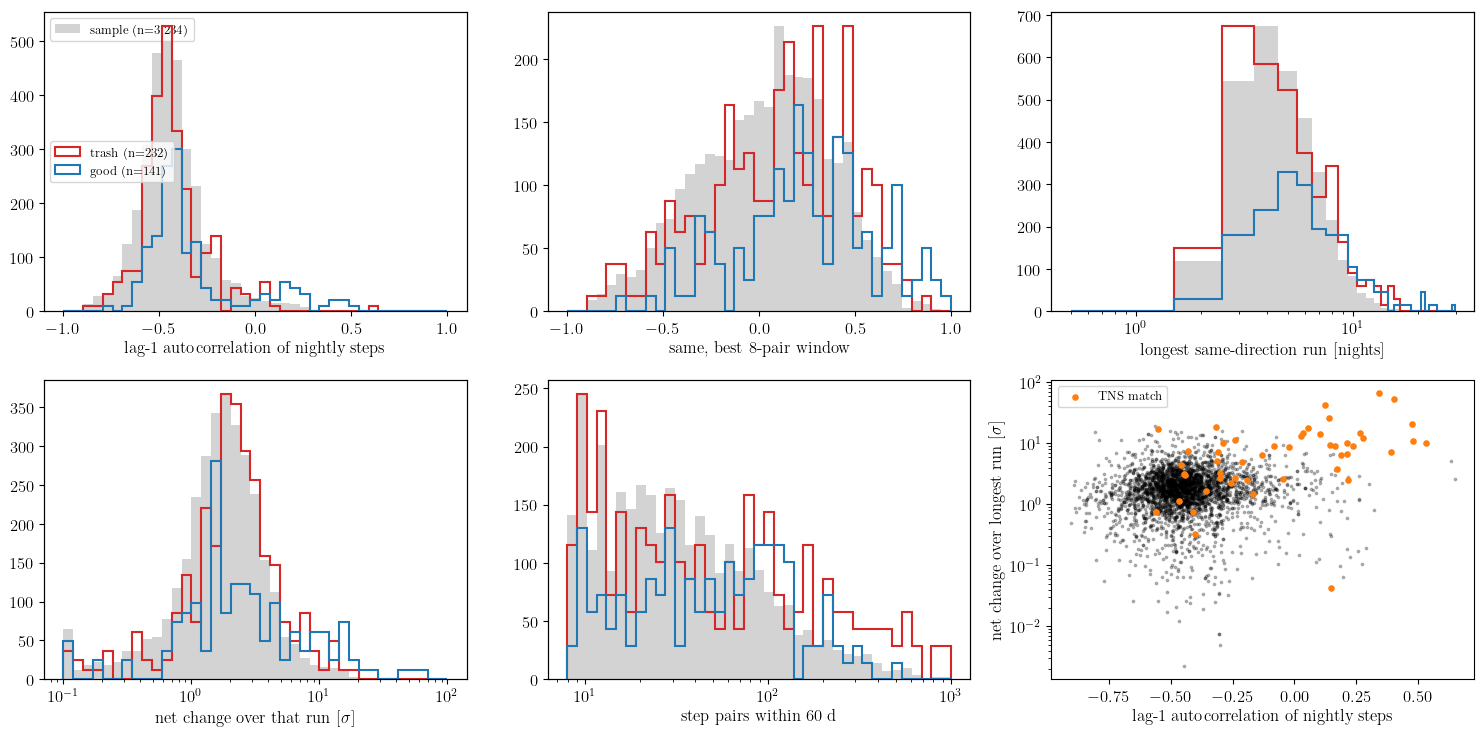

In [49]:
grp = sample.source_uuid.map(src.set_index('source_uuid').grp).fillna('unlabelled')
panels = [('diff_acf1', 'lag-1 autocorrelation of nightly steps', np.linspace(-1, 1, 40)),
          ('diff_acf1_max', 'same, best 8-pair window', np.linspace(-1, 1, 40)),
          ('longest_run', 'longest same-direction run [nights]', np.arange(0.5, 30.5, 1)),
          ('run_sigma', r'net change over that run [$\sigma$]', np.logspace(-1, 2, 40)),
          ('same_sign', 'fraction of consecutive steps agreeing in direction', np.linspace(0, 1, 40))]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, (col, label, bins) in zip(axes.flat, panels):
    v = sample[col].dropna().clip(bins[0], bins[-1])
    ax.hist(v, bins=bins, color='lightgray', label=f'sample (n={len(v):,})')
    ax2 = ax.twinx()
    for k, c in [('trash', 'C3'), ('good', 'C0')]:
        vv = sample.loc[grp == k, col].dropna().clip(bins[0], bins[-1])
        ax2.hist(vv, bins=bins, histtype='step', lw=1.5, color=c, label=f'{k} (n={len(vv)})')
    ax2.set_yticks([]); ax.set_xlabel(label)
    if bins[0] > 0 and bins[1] / bins[0] > 1.05: ax.set_xscale('log')
    if col == 'diff_acf1': ax.legend(loc='upper left', fontsize=9); ax2.legend(loc='center left', fontsize=9)
ax = axes.flat[-1]
ax.scatter(sample.diff_acf1, sample.run_sigma, s=3, c='k', alpha=0.25)
ax.scatter(sample.loc[tns, 'diff_acf1'], sample.loc[tns, 'run_sigma'], s=14, c='C1', label='TNS match')
ax.set_yscale('log'); ax.set_xlabel('lag-1 autocorrelation of nightly steps'); ax.set_ylabel(r'net change over longest run [$\sigma$]'); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()